In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import PartialDependenceDisplay
import matplotlib.pyplot as plt

from pathlib import Path

DATA_PATH = Path("../data/raw/dataset.csv")

df = pd.read_csv(DATA_PATH)

df.head()

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [14]:
df.columns
df = df.drop(columns=["Unnamed: 0"], errors="ignore")

df.head()

features = [
    "duration_ms",
    "danceability",
    "energy",
    "loudness",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo"
]

target = "popularity"

data = df[features + [target]].dropna()

X = data[features]
y = data[target]

X.shape, y.shape

((114000, 10), (114000,))

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)
model = RandomForestRegressor(
    n_estimators=100,
    max_depth=12,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

,n_estimators,100
,criterion,'squared_error'
,max_depth,12
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [16]:
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred) ** 0.5
r2 = r2_score(y_test, y_pred)

print(f"MAE: {mae:.3f}")
print(f"RMSE: {rmse:.3f}")
print(f"R²: {r2:.3f}")

MAE: 15.857
RMSE: 19.583
R²: 0.223


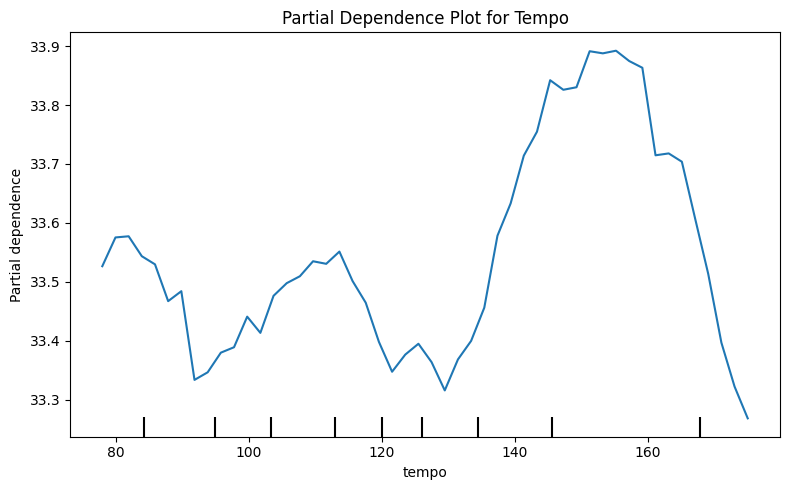

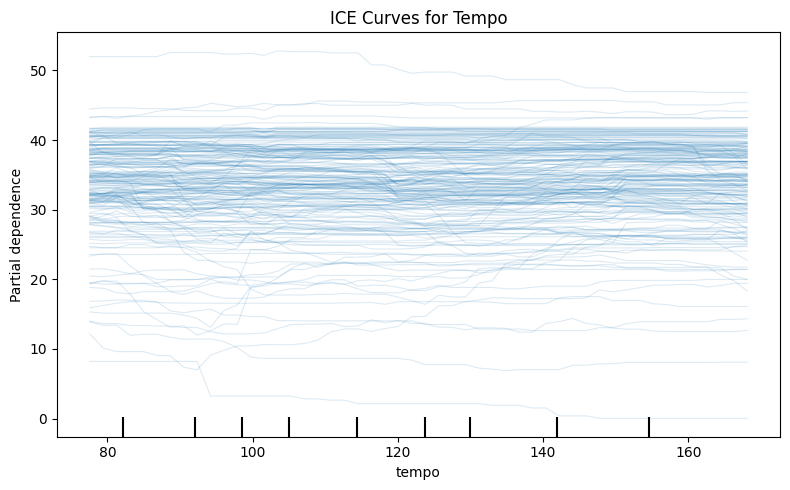

In [17]:
#pdp
X_pdp = X_test.sample(n=2000, random_state=42)

fig, ax = plt.subplots(figsize=(8, 5))

PartialDependenceDisplay.from_estimator(
    model,
    X_pdp,
    features=["tempo"],
    kind="average",
    grid_resolution=50,
    ax=ax
)

ax.set_title("Partial Dependence Plot for Tempo")
ax.set_xlabel("Tempo (BPM)")
ax.set_ylabel("Predicted Popularity")

plt.tight_layout()
plt.savefig("../figures/pdp_tempo.png", dpi=300, bbox_inches="tight")
plt.show()

#ice
X_ice = X_test.sample(n=200, random_state=42)

fig, ax = plt.subplots(figsize=(8, 5))

PartialDependenceDisplay.from_estimator(
    model,
    X_ice,
    features=["tempo"],
    kind="individual",
    grid_resolution=50,
    ax=ax,
    ice_lines_kw={"alpha": 0.15, "linewidth": 0.8}
)

ax.set_title("ICE Curves for Tempo")
ax.set_xlabel("Tempo (BPM)")
ax.set_ylabel("Predicted Popularity")

plt.tight_layout()
plt.savefig("../figures/ice_tempo.png", dpi=300, bbox_inches="tight")
plt.show()

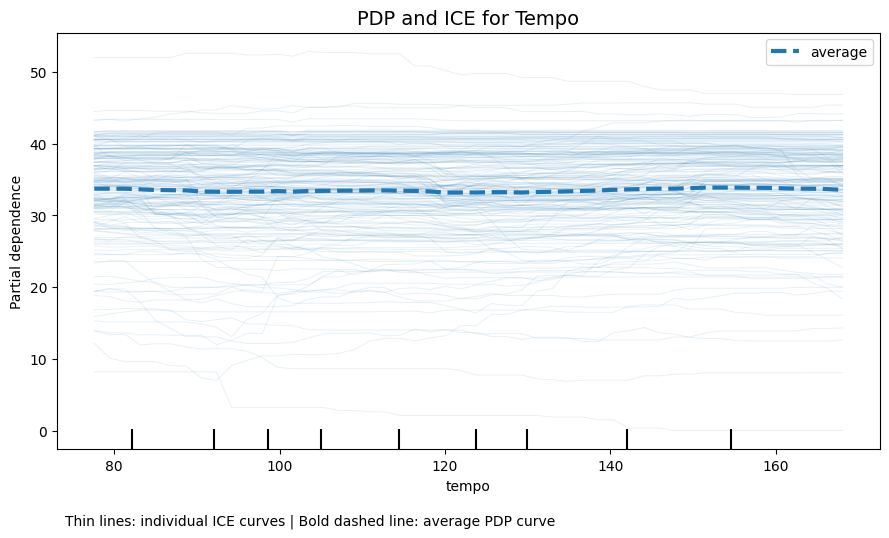

In [19]:
fig, ax = plt.subplots(figsize=(9, 5.5))

PartialDependenceDisplay.from_estimator(
    model,
    X_ice,
    features=["tempo"],
    kind="both",
    grid_resolution=50,
    ax=ax,
    ice_lines_kw={"alpha": 0.10, "linewidth": 0.7},
    pd_line_kw={"linewidth": 3}
)

ax.set_title("PDP and ICE for Tempo", fontsize=14)
ax.set_xlabel("Tempo (BPM)")
ax.set_ylabel("Predicted Popularity")

ax.text(
    0.01,
    -0.18,
    "Thin lines: individual ICE curves | Bold dashed line: average PDP curve",
    transform=ax.transAxes,
    fontsize=10
)

plt.tight_layout()
plt.savefig("../figures/pdp_ice_tempo_combined_clean.png", dpi=300, bbox_inches="tight")
plt.show()